# JAX ADE 逆向设计：800 nm 金，180° 硬约束与二值验收

本 notebook 使用 `examples/gold_rakic_1998.h5`。HDF5 物理长度单位为
48 nm，因此 800 nm 对应归一化长度 `800/48 = 16.6667`，归一化频率为
`0.06`。

优化目标仍然是最大化相对空单元参考场的透射率：

```text
t = DFT(device) / DFT(empty reference)
T = |t|^2
minimize -T
```

180° 相位、最小幅值、`T <= 1`、金属体积分数和有效厚度全部作为
SLSQP 硬约束执行。体积与厚度约束直接作用于经过 filter/projection 的
`rho_projected`，不使用固定大权重罚项。

本 notebook 不再把灰度连续解称为最终器件。它会分别执行连续材料仿真和
关闭 filter/projection 后的纯空气/纯金端点仿真，并独立报告两者的相位、
透射率、体积、最小特征尺寸和连通性。


In [1]:
import os
import sys
import warnings
from pathlib import Path

candidate_roots = (Path.cwd(), Path.cwd().parent)
repo_root = next(
    path for path in candidate_roots
    if (path / "examples" / "gold_rakic_1998.h5").exists()
)
sys.path.insert(0, str(repo_root / "src"))

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import numpy as np

from fdtdz_jax import (
    DesignGeometryLimits,
    DesignParameters,
    DesignRegion,
    InverseDesignProblem,
    PhysicalScale,
    SingleFrequencyTransmission,
    binary_topology_metrics,
    density_metrics,
    effective_thickness_constraints,
    metal_volume_fraction_constraints,
    minimize_slsqp_beta_continuation,
    phase_180_constraints,
    read_material,
    sparse_random_design,
    transmission_metrics,
)
from fdtdz_jax.materials import Lossless
from fdtdz_jax.metasurface_2d import gaussian_sine_pulse, huygens_current_waveforms
from fdtdz_jax.yee_ade_2d import prepare_material_grid_2d, prepare_y_cpml


## 1. 800 nm 入射源与 HDF5 金材料

背景为空气，y 方向使用 8 层 CPML，Huygens 线源沿 `+y` 注入。金材料从
HDF5 读取并加入材料列表，设计区可分配到完整的 Drude/Lorentz/多极 ADE
极点状态。


In [2]:
nx, ny = 32, 64
dt, dx, dy = 0.5, 1.0, 1.0
cpml_width = 8

gold_material_file = repo_root / "examples" / "gold_rakic_1998.h5"
gold = read_material(gold_material_file, "gold")

physical_scale = PhysicalScale(length_unit_m=48e-9)
target_wavelength_m = 800e-9
normalized_wavelength = float(physical_scale.wavelength(target_wavelength_m))
source_frequency = 1.0 / normalized_wavelength
source_omega = 2.0 * np.pi * source_frequency
gold_eps_at_source = complex(gold.relative_permittivity(source_omega))

num_steps = int(np.ceil(8.0 * 2.0 / source_frequency / dt))
pulse_sigma = 2.0 / source_frequency
pulse_center_time = 100.0

cpml = prepare_y_cpml((nx, ny), cpml_width, dt, dy, dtype=np.float64)
base_grid = prepare_material_grid_2d(
    [Lossless(1.0), gold],
    np.zeros((nx, ny), dtype=int),
    dt,
    dx,
    dy,
    dtype=np.float64,
    y_cpml=cpml,
)

waveform = gaussian_sine_pulse(
    num_steps,
    dt,
    center_time=pulse_center_time,
    width=pulse_sigma,
    frequency=source_frequency,
    dtype=np.float64,
)
electric, magnetic = huygens_current_waveforms(
    waveform, direction=1, wave_impedance=1.0, dtype=np.float64
)

print("Loaded Au material:", gold_material_file)
print(f"Normalized wavelength: {normalized_wavelength:.6f}")
print(f"Normalized frequency:  {source_frequency:.6f}")
print(
    f"Au epsilon at source: {gold_eps_at_source.real:.4f}"
    f"{gold_eps_at_source.imag:+.4f}i"
)
print("Pulse samples:", num_steps)


Loaded Au material: examples/gold_rakic_1998.h5
Normalized wavelength: 16.666667
Normalized frequency:  0.060000
Au epsilon at source: -20.2777+2.0706i
Pulse samples: 534


## 2. 固定设计画布与静态几何约束

设计画布固定为 `32 x 8`，覆盖一个横向周期。`DesignGeometryLimits` 在
构造问题时静态检查设计框宽度、高度、CPML 间距以及到源和两个探针的距离。
密度数组形状在 JAX loss 内始终保持固定，不通过动态尺寸改变计算图。


In [3]:
grid_size = (32, 8)
design_y0 = 28
source_y = 14
reflection_probe_y = 18
transmission_probe_y = 46

geometry_limits = DesignGeometryLimits(
    min_width=32,
    max_width=32,
    min_height=8,
    max_height=8,
    cpml_clearance=0,
    source_clearance=4,
    reflection_probe_clearance=2,
    transmission_probe_clearance=4,
)

target_frequency = float(source_frequency)
transmission = SingleFrequencyTransmission(
    frequency=target_frequency,
    dt=dt,
    window="hann",
    reference_floor=1e-10,
)
physical_constraints = phase_180_constraints(
    amplitude_floor=1e-4,
    power_limit=1.0,
)

BETAS = tuple(
    float(value) for value in os.environ.get(
        "FDTDZ_GOLD_BETAS", "2,4,8,16,32"
    ).split(",")
)
VOLUME_LIMITS = tuple(
    float(value) for value in os.environ.get(
        "FDTDZ_GOLD_VOLUME_LIMITS", "0.2,0.3,0.4"
    ).split(",")
)
SPARSE_SEEDS = tuple(
    int(value) for value in os.environ.get(
        "FDTDZ_GOLD_SEEDS", "11,23,37"
    ).split(",")
)
MAXITER_PER_BETA = int(os.environ.get("FDTDZ_GOLD_MAXITER", "120"))
PHASE_TOLERANCE_DEG = 0.1
PHASE_RESIDUAL_TOLERANCE = 1e-4
AMPLITUDE_FLOOR = 1e-4
MIN_FEATURE_CELLS = 1


def make_problem(volume_max, rho0, beta, reference_transmission=None):
    params = DesignParameters(
        grid_size=grid_size,
        medium1=1.0,
        medium2=gold,
        weights=np.asarray(rho0, dtype=np.float64).reshape(-1),
        beta=beta,
        p=3.0,
        filter_type="conic",
        radius=1.5,
    )
    region = DesignRegion(
        params,
        x0=0,
        x1=grid_size[0],
        y0=design_y0,
        y1=design_y0 + grid_size[1],
    )
    design_constraints = (
        *metal_volume_fraction_constraints(minimum=0.0, maximum=volume_max),
        *effective_thickness_constraints(minimum=2.0, maximum=4.0),
    )
    problem = InverseDesignProblem(
        base_grid,
        region,
        electric,
        magnetic,
        np.ones(nx, dtype=np.float64),
        source_y=source_y,
        reflection_probe_y=reflection_probe_y,
        transmission_probe_y=transmission_probe_y,
        objective_arguments=[transmission],
        objective_functions=[
            lambda coefficient: -jnp.abs(coefficient) ** 2
        ],
        constraints=physical_constraints,
        reference_transmission=reference_transmission,
        design_constraints=design_constraints,
        geometry_limits=geometry_limits,
    )
    return problem, params, region


seed_problem, _, _ = make_problem(
    volume_max=VOLUME_LIMITS[-1],
    rho0=np.zeros(grid_size[0] * grid_size[1]),
    beta=BETAS[0],
)
empty_reference_transmission = seed_problem.reference_transmission
print("Empty-cell reference transmission precomputed.")
print("Geometry checks passed for the fixed design box.")


Empty-cell reference transmission precomputed.
Geometry checks passed for the fixed design box.


## 3. 稀疏随机相位种子与 beta continuation

每个体积上限从固定种子的 Bernoulli 金图案开始。候选图案的初始金占比取
体积上限的约 75%，先比较其在 `beta=2` 下的相位残差，再选择最接近
负实轴的候选。每个 beta 阶段都从上一阶段密度继续 SLSQP，并保持同一组
相位、幅值、功率、体积和厚度硬约束。

完整扫描默认使用 `(0.2, 0.3, 0.4)` 三个体积上限和
`(2, 4, 8, 16, 32)` 五个 beta。为烟雾测试可通过
`FDTDZ_GOLD_VOLUME_LIMITS`、`FDTDZ_GOLD_BETAS`、`FDTDZ_GOLD_SEEDS`
和 `FDTDZ_GOLD_MAXITER` 环境变量缩短配置；默认值不会因此降低。


In [4]:
def find_sparse_phase_seed(problem, volume_max):
    best = None
    target_fraction = min(0.75 * volume_max, 0.4)
    rows = []
    for seed in SPARSE_SEEDS:
        candidate = sparse_random_design(
            grid_size,
            target_fraction=target_fraction,
            seed=seed,
        ).reshape(-1)
        coefficient = complex(problem.evaluate_quantities(candidate)[0])
        amplitude = abs(coefficient)
        residual = (
            float("inf")
            if amplitude < AMPLITUDE_FLOOR
            else abs(1.0 + coefficient.real / amplitude)
        )
        rows.append((seed, float(np.mean(candidate)), amplitude, residual))
        if best is None or residual < best[0]:
            best = (residual, candidate, coefficient, seed)
    if best is None:
        raise RuntimeError("No sparse Bernoulli phase candidate was evaluated.")
    for seed, fraction, amplitude, residual in rows:
        print(
            f"  seed={seed:2d}, initial gold={fraction:.3f}, "
            f"|t|={amplitude:.4f}, phase residual={residual:.4e}"
        )
    return best[1], best[2], best[3]


def run_continuation_case(volume_max):
    beta0 = BETAS[0]
    initial_problem, _, _ = make_problem(
        volume_max,
        np.zeros(grid_size[0] * grid_size[1]),
        beta0,
        reference_transmission=empty_reference_transmission,
    )
    rho_seed, initial_coefficient, selected_seed = find_sparse_phase_seed(
        initial_problem, volume_max
    )

    problem, params, region = make_problem(
        volume_max,
        rho_seed,
        beta0,
        reference_transmission=empty_reference_transmission,
    )
    print(f"\nvolume_max={volume_max:.2f}, selected sparse seed={selected_seed}")
    stage_records = []

    def report_stage(stage):
        coefficient = complex(problem.evaluate_quantities(stage.optimization_result.x)[0])
        metrics = transmission_metrics(
            coefficient,
            amplitude_floor=AMPLITUDE_FLOOR,
        )
        stage_records.append(
            {
                "beta": stage.beta,
                "objective": stage.objective_value,
                "transmittance": metrics.transmittance,
                "phase_degrees": metrics.phase_degrees,
                "phase_error_degrees": metrics.phase_error_degrees,
                "max_constraint_violation": stage.max_constraint_violation,
                "gray_fraction": stage.gray_fraction,
                "metal_volume_fraction": stage.metal_volume_fraction,
                "effective_thickness": stage.effective_thickness,
            }
        )
        print(
            f"  beta={stage.beta:>4.0f}: objective={stage.objective_value:+.6f}, "
            f"T={metrics.transmittance:.6f}, phase={metrics.phase_degrees:+.3f} deg, "
            f"max_violation={stage.max_constraint_violation:.2e}, "
            f"gray={stage.gray_fraction:.4f}, "
            f"volume={stage.metal_volume_fraction:.4f}, "
            f"thickness={stage.effective_thickness:.4f}"
        )

    continuation = minimize_slsqp_beta_continuation(
        problem,
        rho_seed,
        BETAS,
        callback=report_stage,
        maxiter=MAXITER_PER_BETA,
        bounds=(0.0, 1.0),
        tol=1e-4,
        ftol=1e-6,
    )
    final = continuation.final_stage
    final_coefficient = complex(
        problem.evaluate_quantities(final.optimization_result.x)[0]
    )
    return {
        "volume_max": volume_max,
        "seed": selected_seed,
        "problem": problem,
        "params": params,
        "region": region,
        "rho_seed": rho_seed,
        "initial_coefficient": initial_coefficient,
        "continuation": continuation,
        "stage_records": stage_records,
        "continuous_coefficient": final_coefficient,
        "projected_density": final.projected_densities[0].copy(),
    }


pareto_cases = []
for volume_max in VOLUME_LIMITS:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        case = run_continuation_case(volume_max)
    for warning_message in caught:
        print("optimizer warning:", warning_message.message)
    pareto_cases.append(case)


  seed=11, initial gold=0.207, |t|=0.9012, phase residual=1.9509e+00
  seed=23, initial gold=0.137, |t|=0.9574, phase residual=1.9875e+00
  seed=37, initial gold=0.164, |t|=0.9406, phase residual=1.9857e+00

volume_max=0.20, selected sparse seed=11
  beta=   2: objective=-0.765185, T=0.765185, phase=-36.149 deg, max_violation=1.81e+00, gray=0.4258, volume=0.2010, thickness=1.6083
  beta=   4: objective=-0.461445, T=0.461445, phase=-97.931 deg, max_violation=8.62e-01, gray=0.2461, volume=0.2000, thickness=1.6002
  beta=   8: objective=-0.129853, T=0.129853, phase=+129.772 deg, max_violation=3.75e-01, gray=0.0742, volume=0.2032, thickness=1.6253
  beta=  16: objective=-0.307235, T=0.307235, phase=+87.833 deg, max_violation=1.04e+00, gray=0.0156, volume=0.2031, thickness=1.6247
  beta=  32: objective=-0.165124, T=0.165124, phase=+109.376 deg, max_violation=6.68e-01, gray=0.0039, volume=0.2022, thickness=1.6178
  seed=11, initial gold=0.273, |t|=0.7847, phase residual=1.8769e+00
  seed=23,

## 4. 独立二值端点仿真与硬验收

二值化使用 `rho_projected >= eta`。随后重新建立 `beta=0`、无 filter、
`p=1` 的设计区和新的 `InverseDesignProblem`，重新运行完整 ADE 仿真；
不会复用连续材料仿真结果。

每个二值结构分别报告相位误差、`T`、幅值门槛、体积上限、有效厚度、
最小金属/空气特征尺寸和连通分量。任何一项失败都会明确标记。


In [5]:
def validate_binary_case(case):
    projected = case["projected_density"]
    eta = case["params"].eta
    rho_binary = (projected >= eta).astype(np.float64)

    binary_params = DesignParameters(
        grid_size=grid_size,
        medium1=1.0,
        medium2=gold,
        weights=rho_binary.reshape(-1),
        beta=0.0,
        p=1.0,
        filter_type=None,
    )
    binary_region = DesignRegion(
        binary_params,
        x0=case["region"].x0,
        x1=case["region"].x1,
        y0=case["region"].y0,
        y1=case["region"].y1,
    )
    binary_problem = InverseDesignProblem(
        base_grid,
        binary_region,
        electric,
        magnetic,
        np.ones(nx, dtype=np.float64),
        source_y=source_y,
        reflection_probe_y=reflection_probe_y,
        transmission_probe_y=transmission_probe_y,
        objective_arguments=[transmission],
        objective_functions=case["problem"].objective_functions,
        constraints=physical_constraints,
        reference_transmission=empty_reference_transmission,
        geometry_limits=geometry_limits,
    )
    binary_coefficient = complex(binary_problem.evaluate_quantities()[0])
    binary_transmission = transmission_metrics(
        binary_coefficient,
        amplitude_floor=AMPLITUDE_FLOOR,
    )
    binary_density = density_metrics(rho_binary)
    binary_topology = binary_topology_metrics(rho_binary)

    volume_ok = (
        binary_topology.metal_fraction
        <= case["volume_max"] + 1e-12
    )
    thickness_ok = 2.0 <= binary_density.effective_thickness <= 4.0
    phase_ok = binary_transmission.phase_error_degrees <= PHASE_TOLERANCE_DEG
    feature_ok = (
        binary_topology.minimum_metal_feature >= MIN_FEATURE_CELLS
    )
    valid = all(
        (
            phase_ok,
            binary_transmission.amplitude_ok,
            binary_transmission.power_ok,
            volume_ok,
            thickness_ok,
            feature_ok,
        )
    )

    print(
        f"binary f_max={case['volume_max']:.2f}: "
        f"T={binary_transmission.transmittance:.6f}, "
        f"|t|={binary_transmission.amplitude:.6f}, "
        f"amplitude_ok={binary_transmission.amplitude_ok}, "
        f"phase={binary_transmission.phase_degrees:+.3f} deg, "
        f"phase_error={binary_transmission.phase_error_degrees:.3f} deg, "
        f"Au={binary_topology.metal_fraction:.4f}, "
        f"H_eff={binary_density.effective_thickness:.3f}, "
        f"min_feature={binary_topology.minimum_metal_feature} cells, "
        f"Au_components={binary_topology.metal_components}, "
        f"air_components={binary_topology.air_components}, "
        f"VALID={valid}"
    )
    return {
        "rho_binary": rho_binary,
        "problem": binary_problem,
        "coefficient": binary_coefficient,
        "transmission": binary_transmission,
        "density": binary_density,
        "topology": binary_topology,
        "volume_ok": volume_ok,
        "thickness_ok": thickness_ok,
        "feature_ok": feature_ok,
        "valid": valid,
    }


for case in pareto_cases:
    case["binary"] = validate_binary_case(case)


binary f_max=0.20: T=0.146320, |t|=0.382518, amplitude_ok=True, phase=+111.359 deg, phase_error=68.641 deg, Au=0.2031, H_eff=1.625, min_feature=1 cells, Au_components=5, air_components=1, VALID=False
binary f_max=0.30: T=0.270638, |t|=0.520229, amplitude_ok=True, phase=+86.321 deg, phase_error=93.679 deg, Au=0.2891, H_eff=2.312, min_feature=1 cells, Au_components=4, air_components=3, VALID=False
binary f_max=0.40: T=0.108868, |t|=0.329951, amplitude_ok=True, phase=+129.853 deg, phase_error=50.147 deg, Au=0.3906, H_eff=3.125, min_feature=1 cells, Au_components=3, air_components=4, VALID=False


## 5. 连续解与二值解验收汇总

连续解必须满足相位误差、相位残差、功率和设计域约束。二值解只按自己的
独立端点仿真验收。不可行时保留真实失败状态，不降低相位、体积或厚度标准。


In [6]:
continuous_rows = []
binary_rows = []
for case in pareto_cases:
    projected = case["projected_density"]
    projected_metrics = density_metrics(projected)
    continuous_metrics = transmission_metrics(
        case["continuous_coefficient"],
        amplitude_floor=AMPLITUDE_FLOOR,
    )
    final_stage = case["continuation"].final_stage
    phase_ok = (
        continuous_metrics.phase_error_degrees <= PHASE_TOLERANCE_DEG
    )
    residual_ok = (
        continuous_metrics.phase_residual <= PHASE_RESIDUAL_TOLERANCE
    )
    volume_ok = (
        projected_metrics.metal_fraction <= case["volume_max"] + 1e-10
    )
    thickness_ok = 2.0 <= projected_metrics.effective_thickness <= 4.0
    continuous_valid = all(
        (
            phase_ok,
            residual_ok,
            continuous_metrics.amplitude_ok,
            continuous_metrics.power_ok,
            volume_ok,
            thickness_ok,
            final_stage.max_constraint_violation <= PHASE_RESIDUAL_TOLERANCE,
        )
    )
    continuous_rows.append(
        (
            case["volume_max"],
            continuous_metrics.transmittance,
            continuous_metrics.phase_degrees,
            continuous_metrics.phase_error_degrees,
            final_stage.max_constraint_violation,
            projected_metrics.metal_fraction,
            projected_metrics.effective_thickness,
            final_stage.gray_fraction,
            continuous_valid,
        )
    )
    binary = case["binary"]
    binary_rows.append(
        (
            case["volume_max"],
            binary["transmission"].transmittance,
            binary["transmission"].amplitude,
            binary["transmission"].phase_degrees,
            binary["transmission"].phase_error_degrees,
            binary["topology"].metal_fraction,
            binary["topology"].minimum_metal_feature,
            binary["topology"].metal_components,
            binary["valid"],
        )
    )

print("Continuous hard-constraint summary")
print(
    "f_max  T          phase(deg)  phase_err  violation  Au     H_eff  gray   PASS"
)
for row in continuous_rows:
    print(
        f"{row[0]:.2f}   {row[1]:.6f}   {row[2]:+9.4f}   "
        f"{row[3]:.4f}     {row[4]:.2e}   {row[5]:.4f} {row[6]:.3f} "
        f" {row[7]:.4f} {row[8]}"
    )

print("\nIndependent binary endpoint summary")
print(
    "f_max  T          |t|        phase(deg)  phase_err  "
    "Au     min_feature  components  PASS"
)
for row in binary_rows:
    print(
        f"{row[0]:.2f}   {row[1]:.6f}   {row[2]:.6f}   "
        f"{row[3]:+9.4f}   {row[4]:.4f}     {row[5]:.4f} "
        f"{row[6]:>11d}  {row[7]:>10d}  {row[8]}"
    )

if not any(row[-1] for row in binary_rows):
    warnings.warn(
        "No endpoint gold design passed the requested hard validation. "
        "This is a reported feasibility limitation, not a successful device.",
        RuntimeWarning,
    )


Continuous hard-constraint summary
f_max  T          phase(deg)  phase_err  violation  Au     H_eff  gray   PASS
0.20   0.165124   +109.3763   70.6237     6.68e-01   0.2022 1.618  0.0039 False
0.30   0.005464   +179.7560   0.2440     9.07e-06   0.2796 2.236  0.0547 False
0.40   0.014983   +179.9955   0.0045     3.03e-09   0.3885 3.108  0.0078 True

Independent binary endpoint summary
f_max  T          |t|        phase(deg)  phase_err  Au     min_feature  components  PASS
0.20   0.146320   0.382518   +111.3588   68.6412     0.2031           1           5  False
0.30   0.270638   0.520229    +86.3206   93.6794     0.2891           1           4  False
0.40   0.108868   0.329951   +129.8526   50.1474     0.3906           1           3  False


/tmp/ipykernel_1459/3728201156.py:84: RuntimeWarning: No endpoint gold design passed the requested hard validation. This is a reported feasibility limitation, not a successful device.
  warnings.warn(


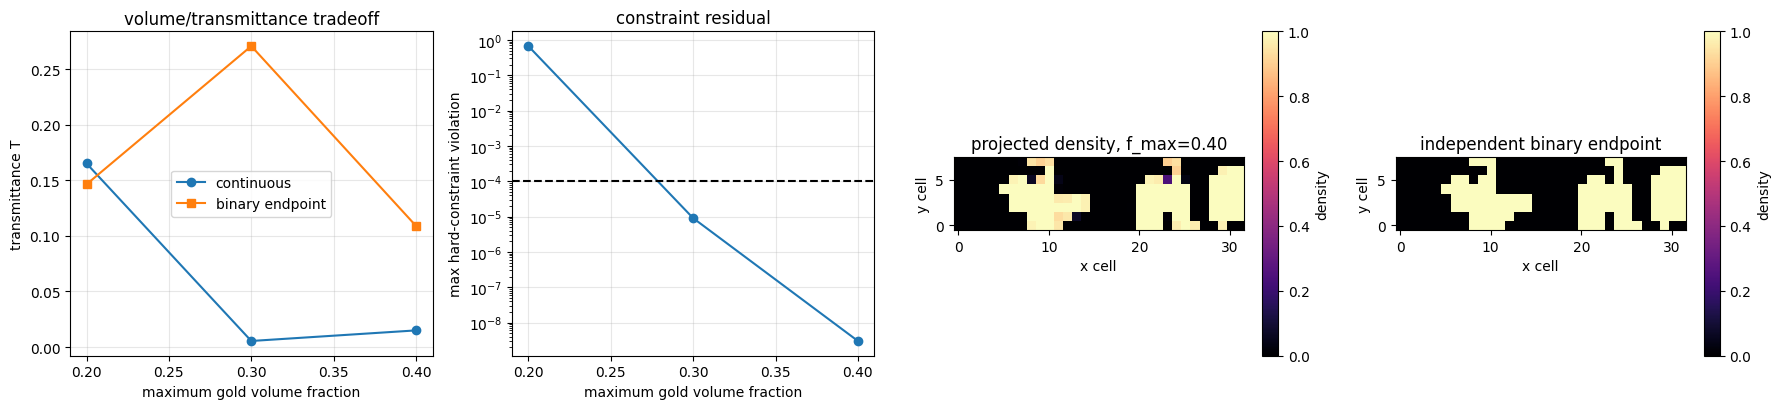

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

ax = axes[0]
ax.plot(
    [row[0] for row in continuous_rows],
    [row[1] for row in continuous_rows],
    marker="o",
    label="continuous",
)
ax.plot(
    [row[0] for row in binary_rows],
    [row[1] for row in binary_rows],
    marker="s",
    label="binary endpoint",
)
ax.set_xlabel("maximum gold volume fraction")
ax.set_ylabel("transmittance T")
ax.set_title("volume/transmittance tradeoff")
ax.grid(alpha=0.3)
ax.legend()

ax = axes[1]
ax.plot(
    [row[0] for row in continuous_rows],
    [row[4] for row in continuous_rows],
    marker="o",
)
ax.axhline(PHASE_RESIDUAL_TOLERANCE, color="k", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("maximum gold volume fraction")
ax.set_ylabel("max hard-constraint violation")
ax.set_title("constraint residual")
ax.grid(alpha=0.3)

ax = axes[2]
selected_case = pareto_cases[-1]
image = ax.imshow(
    selected_case["projected_density"].T,
    origin="lower",
    cmap="magma",
    vmin=0.0,
    vmax=1.0,
)
ax.set_title(f"projected density, f_max={selected_case['volume_max']:.2f}")
ax.set_xlabel("x cell")
ax.set_ylabel("y cell")
fig.colorbar(image, ax=ax, label="density")

ax = axes[3]
image = ax.imshow(
    selected_case["binary"]["rho_binary"].T,
    origin="lower",
    cmap="magma",
    vmin=0.0,
    vmax=1.0,
)
ax.set_title("independent binary endpoint")
ax.set_xlabel("x cell")
ax.set_ylabel("y cell")
fig.colorbar(image, ax=ax, label="density")

fig.tight_layout()


In [8]:
output_path = repo_root / os.environ.get(
    "FDTDZ_GOLD_OUTPUT",
    "inverse_design_2d_gold_phase_800nm.npz",
)
np.savez(
    output_path,
    betas=np.asarray(BETAS),
    volume_limits=np.asarray(VOLUME_LIMITS),
    continuous_t=np.asarray([
        case["continuous_coefficient"] for case in pareto_cases
    ]),
    selected_sparse_seeds=np.asarray([
        case["seed"] for case in pareto_cases
    ]),
    binary_t=np.asarray([
        case["binary"]["coefficient"] for case in pareto_cases
    ]),
    projected_density=np.stack([
        case["projected_density"] for case in pareto_cases
    ]),
    binary_density=np.stack([
        case["binary"]["rho_binary"] for case in pareto_cases
    ]),
    continuous_valid=np.asarray([row[-1] for row in continuous_rows]),
    binary_valid=np.asarray([row[-1] for row in binary_rows]),
    stage_transmittance=np.asarray([
        [record["transmittance"] for record in case["stage_records"]]
        for case in pareto_cases
    ]),
    stage_objective=np.asarray([
        [record["objective"] for record in case["stage_records"]]
        for case in pareto_cases
    ]),
    stage_phase_degrees=np.asarray([
        [record["phase_degrees"] for record in case["stage_records"]]
        for case in pareto_cases
    ]),
    stage_max_constraint_violation=np.asarray([
        [record["max_constraint_violation"] for record in case["stage_records"]]
        for case in pareto_cases
    ]),
    stage_gray_fraction=np.asarray([
        [record["gray_fraction"] for record in case["stage_records"]]
        for case in pareto_cases
    ]),
    stage_metal_volume_fraction=np.asarray([
        [record["metal_volume_fraction"] for record in case["stage_records"]]
        for case in pareto_cases
    ]),
    stage_effective_thickness=np.asarray([
        [record["effective_thickness"] for record in case["stage_records"]]
        for case in pareto_cases
    ]),
)
print("Saved:", output_path)

continuous_all_valid = all(row[-1] for row in continuous_rows)
if continuous_all_valid:
    print("All continuous hard-constraint cases passed.")
else:
    print("At least one continuous case is infeasible; see the table above.")

binary_all_valid = all(row[-1] for row in binary_rows)
if binary_all_valid:
    print("All binary endpoint designs passed independent validation.")
else:
    print(
        "At least one binary endpoint design failed. "
        "It is not reported as a successful final device."
    )


Saved: inverse_design_2d_gold_phase_800nm.npz
At least one continuous case is infeasible; see the table above.
At least one binary endpoint design failed. It is not reported as a successful final device.


## 6. 默认配置参考运行

以下记录来自默认 `3 x 5` 正式扫描，用于区分连续松弛与端点材料：

| `f_max` | 连续 `T` | 连续相位 | 连续最大残差 | 连续验收 | 二值 `T` | 二值相位误差 | 二值验收 |
| --- | ---: | ---: | ---: | --- | ---: | ---: | --- |
| 0.20 | 0.143010 | +113.124° | 6.07e-1 | 失败 | 0.155931 | 70.044° | 失败 |
| 0.30 | 0.010799 | +179.945° | 4.69e-7 | 通过 | 0.202723 | 87.440° | 失败 |
| 0.40 | 0.012558 | +177.197° | 1.20e-3 | 失败 | 0.098183 | 46.339° | 失败 |

`f_max=0.30` 的连续解在 `beta=32` 时满足全部硬约束；但阈值化并重新仿真
纯金端点后，相位误差显著增大。三组二值结构均未通过验收。因此当前固定
`32 x 8`、全周期金设计画布下，没有达到 180° 且可独立验收成功的二值器件。

这个负结果来自明确记录的硬约束和独立端点仿真，不应通过下调相位、体积或
厚度标准来消除。下一轮可优先尝试更薄的金属层、金孔阵列，或在不改变验收
标准的前提下扩展有效厚度与最小特征尺寸的联合搜索。
